# Biome Exercise Part 5 - Random Forest Regression for NPP and VegC

Includes the following functions:

* **prepare_spatial_splits**(): creates training and testing data splits based on provided hold out area

* **dummies**(): creates dummy variables out of non-numerical variable or categorical

* **create_spatial_grid_groups**(): creates k-folds containing square areas with random locations

* **run_RFRegress_CV**(): runs the random forest regression with cross validation on k-folds

* **plot_var**(): plots a variable on a map

* **execute**(): function to call to execute the above functions in sequence, including creating 

Some arguments can be passed to `execute()`, such as the hold out area, the target variable and the number of folds for CV. Alternatively, other arguments for CV, specifically those for spatial cross validation and other RF parameters, should be adjusted inside the function `run_RFRegress_CV()`. Additionally, the random number generators all use the same seed which is defined once at the top of the notebook (below imports). The seed can be adjusted there and does not need to be changed anywhere else. 

Plots for NPP and VegC regressions with hold-out region 'Americas' are all included below, as well as some other regions, which have been commented for now. Feature importance for the Americas models are included.

Parameter optimization is done in this case for the NPP model with hold-out area Americas (X_train_npp_am and y_train_npp_am). Previously, parameters were optimized on the same region for both the NPP and the VegC models. The results were the same, therefore the same parameters are used for both models in the standard version of the `run_RFRegress_CV()` function. The code for the gridsearch parameter optimization is included, but takes some time to run, so is commented by default. 

Finally, in this entire approach, as of yet, the Middle East is excluded from the data, because data is selected based on the columns UN, Ecoregion, Pan_2007, ISO3, GFED-region, in which those countries are not included. This means that the soil, precipitation, temperature and swr data are not included in training. 

#### 1. Imports

In [2]:
import pandas as pd
import cartopy.crs as ccrs # Enables geographic mapping, e.g., drawing coastlines, etc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import numpy as np
from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import RandomizedSearchCV


In [3]:
proj = ccrs.PlateCarree()
random_seed = 42

biome_codes = {'Boreal decid forest' : 1,
               'Boreal ever forest' : 2,
               'Temp/boreal mix fo.' : 3, 
               'Temp conifer forest' : 4,
               'Temp decid forest' : 5,
               'Temp broad ever fo.': 6,
               'Temp mixed forest' : 7,
               'Trop season forest' : 8,
               'Trop rain forest' : 9,
               'Trop decid forest' : 10,
               'Moist savannas' : 11,
               'Dry savannas' : 12,
               'Tall grassland' : 13,
               'Dry grassland' : 14,
               'Xeric wood/shrub' : 15,
               'Arid shrub/steppe' : 16,
               'Desert' : 17,
               'Arctic/alpine tundra' : 18
               }

#### 2. Data splitting into train and test

In [4]:
# Load LPJ-GUESS & metadata
df_lpj = pd.read_csv(r'data\LPJ-GUESS_output_BERN1.csv')
df_grid = pd.read_csv('gridlist_pan_gfed_ISO3_UN_ecoregion.txt', sep=r'\s+')
df_soil = pd.read_csv('data/soilmap.dat', sep=r'\s+')
df_soil = df_soil.rename(columns={'lon': 'Lon', 'lat': 'Lat'})  # Change column name to match the other data

# Load seasonal climate stats (SpringMean, SummerMean, FallMean, WinterMean, etc.)
df_tmp_stats = pd.read_csv(r'data\Tmpdaymean1961_1990_stats.csv')
df_pre_stats = pd.read_csv(r'data\Predaymean1961_1990_stats.csv')
df_swrf_stats = pd.read_csv(r'data\Tswrfdaymean1961_1990_stats.csv')

# Helper function to add prefixes to non-coordinate columns
def prefix_cols(df, prefix):
    return df.rename(columns={c: f"{prefix}_{c}" for c in df.columns if c not in ['Lon', 'Lat']})

# Load climate stats and apply prefixes immediately
df_tmp_stats = prefix_cols(pd.read_csv(r'data\Tmpdaymean1961_1990_stats.csv'), 'Tmp')
df_pre_stats = prefix_cols(pd.read_csv(r'data\Predaymean1961_1990_stats.csv'), 'Pre')
df_swrf_stats = prefix_cols(pd.read_csv(r'data\Tswrfdaymean1961_1990_stats.csv'), 'Tswrf')

# Load LPJ, Grid, and Soil
df_lpj = pd.read_csv(r'data\LPJ-GUESS_output_BERN1.csv')
df_grid = pd.read_csv('gridlist_pan_gfed_ISO3_UN_ecoregion.txt', sep=r'\s+')
df_soil = pd.read_csv('data/soilmap.dat', sep=r'\s+').rename(columns={'lon': 'Lon', 'lat': 'Lat'})

# Merge everything cleanly without any column name collision
df_master = df_lpj.merge(df_grid, on=['Lon', 'Lat'], how='inner')
df_master = df_master.merge(df_soil, on=['Lon', 'Lat'], how='inner')
df_master = df_master.merge(df_tmp_stats, on=['Lon', 'Lat'], how='inner')
df_master = df_master.merge(df_pre_stats, on=['Lon', 'Lat'], how='inner')
df_master = df_master.merge(df_swrf_stats, on=['Lon', 'Lat'], how='inner')

df_master = df_master.dropna(subset=['Biome_obs']).copy()

In [5]:
def prepare_spatial_splits(
    df: pd.DataFrame, 
    target_var: str = 'NPP', 
    test_region: str | list = 'CHL', 
    ):

    non_feature = ['Lon', 'Lat', 'ISO3', 'GFED-region', 'Pan_2007', 'UN', 'Ecoregion']
    lpj_features = ['NPP' ,'SoilR', 'MaxBiomeCmax', 'MaxBiomeLAI', 'VegC', 'LitterC', 'SoilC', 'Biome_Cmax', 'Biome_LAI', 'Biome_obs']
    feature_cols = [name for name in df.columns if name not in non_feature + lpj_features]
    if target_var in feature_cols:
        feature_cols.remove(target_var)
    
    regions = [test_region] if isinstance(test_region, str) else test_region
    is_test = df['ISO3'].isin(regions) | df['Pan_2007'].isin(regions)

    # Clean rows missing the target variable
    df_test = df[is_test].dropna(subset=[target_var]).copy()
    df_train_val = df[~is_test].dropna(subset=[target_var]).copy()
    
    if df_test.empty:
        raise ValueError(f"No valid rows found for region(s): {regions}")
        
    # Crucial: Reset index across all test splits so row 0 = entry 0 everywhere
    X_test = df_test[feature_cols].reset_index(drop=True)
    y_test = df_test[target_var].reset_index(drop=True)
    coords_test = df_test[['Lon', 'Lat']].reset_index(drop=True)

    X_train = df_train_val[feature_cols].reset_index(drop=True)
    y_train = df_train_val[target_var].reset_index(drop=True)
    
    print(f"--- Data Split Summary [{target_var} | Region: {test_region}] ---")
    print(f"Train: {X_train.shape[0]} entries | Test: {X_test.shape[0]} entries")
    
    return X_train, y_train, X_test, y_test, coords_test

#### 2. Functions for processing and plotting

In [6]:
def dummies(Xdatas: list, non_numeric_cols):
    '''
    Xdatas: list
            the X_train, X_test (and X_val) data
    '''
    # Use the training categories so both splits use the same baseline/category set
    biome_categories = Xdatas[0]["Biome_obs"].dropna().unique()

    for X in Xdatas:
        X["Biome_obs"] = pd.Categorical(
            X["Biome_obs"],
            categories=biome_categories,
        )

    dummyXs = []

    for i, X in enumerate(Xdatas):
        dummyXs.append(pd.get_dummies(
           X, columns=["Biome_obs"], drop_first=True, dtype=int
            ))

    return dummyXs

In [6]:
def create_spatial_grid_groups(df_train, grid_size=5.0, n_splits=5, random_state=random_seed):
    """
    Assigns folds based on a global coordinate grid, ensuring solid rectangular blocks.
    """
    
    df = df_train.copy()
    
    # 1. Bin coordinates into global grid IDs
    df['lon_bin'] = np.floor(df['Lon'] / grid_size)
    df['lat_bin'] = np.floor(df['Lat'] / grid_size)
    
    # 2. Get unique global grid cells that actually exist in the dataset
    grid_cells = df[['lon_bin', 'lat_bin']].drop_duplicates().reset_index(drop=True)
    
    # 3. Randomly shuffle and assign folds to the grid cells
    rng = np.random.default_rng(random_state)
    grid_cells['fold'] = rng.permutation(len(grid_cells)) % n_splits
    
    # 4. Merge back to the main dataframe
    df_merged = df.merge(grid_cells, on=['lon_bin', 'lat_bin'], how='left')
    
    return df_merged['fold']

In [7]:
def run_RFRegress_CV(
    traintest: list, 
    coords_test: pd.DataFrame = None, 
    groups_train: pd.Series = None,
    n_splits: int = 5, 
    use_spatial_groups: bool = True,
    **rf_kwargs
):
    '''
    Runs a Random Forest Regressor with Cross-Validation, storing fold models 
    and ensembling their predictions for the final held-out test set.
    '''
    X_train, y_train, X_test, y_test = traintest
    
    # 1. Handle Categoricals / Dummies
    non_numeric_cols = X_train.select_dtypes(exclude=['number']).columns.tolist()
    if non_numeric_cols:
        X_train, X_test = dummies([X_train, X_test], non_numeric_cols)
        
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0).reset_index(drop=True)

    # 2. Setup CV Strategy
    if use_spatial_groups and groups_train is not None:
        print(f"--- Running GroupKFold CV ({n_splits} splits) based on spatial groups ---")
        cv = GroupKFold(n_splits=n_splits)
        cv_splits = cv.split(X_train, y_train, groups=groups_train)
    else:
        print(f"--- Running standard KFold CV ({n_splits} splits) ---")
        cv = KFold(n_splits=n_splits, shuffle=True, random_state=rf_kwargs.get('random_state', 42))
        cv_splits = cv.split(X_train, y_train)

    # 3. Cross-Validation Loop & Model Collection
    cv_scores = []
    trained_models = []  # <-- Store models from each fold
    
    for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
        X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
        
        model_fold = RandomForestRegressor(**rf_kwargs)
        model_fold.fit(X_tr, y_tr)
        
        # Save the trained model for this fold
        trained_models.append(model_fold)
        
        val_preds = model_fold.predict(X_val)
        fold_mse = mean_squared_error(y_val, val_preds)
        cv_scores.append(fold_mse)
        fold_rmse = np.sqrt(fold_mse)
        print(f"  Fold {fold} Validation RMSE: {fold_rmse:.4f}")

    print(f"Mean CV RMSE: {np.mean(cv_scores):.4f} +/- {np.std(cv_scores):.4f}\n")

    # 4. Ensemble Predictions Across All Spatial Fold Models
    print("Making test predictions using ensemble of spatial fold models...")
    test_preds_per_fold = [model.predict(X_test) for model in trained_models]
    predictions = np.mean(test_preds_per_fold, axis=0)  # Average the predictions from all k folds
    
    y_test_array = y_test.to_numpy()
    error = predictions - y_test_array
    test_mse = mean_squared_error(y_test_array, predictions)
    test_rmse = np.sqrt(test_mse)

    # 5. Build Output DataFrame with Coordinates for Plotting
    if coords_test is not None:
        preds_df = coords_test.copy().reset_index(drop=True)
    else:
        preds_df = pd.DataFrame()
        
    preds_df['obs'] = y_test_array
    preds_df['pred'] = predictions
    preds_df['error'] = error

    print(f"Finished! Final Held-Out Test RMSE: {test_rmse:.4f}")
    
    # Return the list of fold models instead of a single final model
    return test_rmse, cv_scores, preds_df, trained_models

In [8]:
def plot_var(df: pd.DataFrame, variable: str, title: str = '', area='world', cmap=None, projection=ccrs.PlateCarree()):
    """
    Plots a single target variable or prediction error for a specified region from a merged DataFrame.
    Automatically handles TwoSlopeNorm and outlier clipping if plotting error variables.
    """
    plot_df = df.copy()
    extent = None

    # 1. Filter region / spatial extent
    if area.lower() != 'world':
        area_upper = area.upper()
        
        if 'ISO3' in df.columns and area_upper in df['ISO3'].values:
            plot_df = df[df['ISO3'] == area_upper]
        elif 'Pan_2007' in df.columns and area in df['Pan_2007'].values:
            plot_df = df[df['Pan_2007'] == area]
        else:
            countries = pd.read_csv('gridlist_pan_gfed_ISO3_UN_ecoregion.txt', sep=r'\s+')
            if area_upper in countries['ISO3'].values:
                coords = countries[countries['ISO3'] == area_upper][['Lon', 'Lat']]
                plot_df = df.merge(coords, on=['Lon', 'Lat'], how='inner')
            elif 'Pan_2007' in countries.columns and area in countries['Pan_2007'].values:
                coords = countries[countries['Pan_2007'] == area][['Lon', 'Lat']]
                plot_df = df.merge(coords, on=['Lon', 'Lat'], how='inner')

        if plot_df.empty:
            raise ValueError(f"Area '{area}' not found in metadata.")

        lon_min, lon_max = plot_df['Lon'].min() - 1, plot_df['Lon'].max() + 1
        lat_min, lat_max = plot_df['Lat'].min() - 1, plot_df['Lat'].max() + 1
        extent = [lon_min, lon_max, lat_min, lat_max]

    # Check that requested variable exists
    if variable not in plot_df.columns:
        raise KeyError(f"Variable '{variable}' not found in DataFrame columns.")

    # 2. Dynamic aspect ratio detection for figure dimensions
    if extent:
        lon_span = max(abs(extent[1] - extent[0]), 0.1)
        lat_span = abs(extent[3] - extent[2])
        aspect_ratio = lat_span / lon_span
    else:
        aspect_ratio = 0.5  # World view aspect ratio

    if aspect_ratio > 1.2:
        figsize = (5, 7)    # Tall figure for elongated countries (e.g., Chile)
    else:
        figsize = (9, 6)    # Standard wide figure for world or wider regions

    # 3. Detect if plotting residual error & set up TwoSlopeNorm + Outlier Clipping
    is_error = any(kw in variable.lower() for kw in ['error', 'diff', 'residual'])
    
    if is_error:
        # Default to a diverging colormap if none provided
        if cmap is None:
            cmap = 'bwr'  # Blue = underprediction (-), White = zero (0), Red = overprediction (+)
            
        # Clip extreme 2nd and 98th percentile outliers to reveal spatial gradient
        val_min = np.percentile(plot_df[variable].dropna(), 2)
        val_max = np.percentile(plot_df[variable].dropna(), 98)
        
        # Ensure 0.0 is captured inside the bounds
        vmin = min(val_min, -0.001)
        vmax = max(val_max, 0.001)
        
        # TwoSlopeNorm forces 0.0 to map strictly to pure white
        norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
    else:
        if cmap is None:
            cmap = 'YlGnBu'
        norm = None  # Standard linear colormap scaling

    # 4. Create single plot figure
    fig, ax = plt.subplots(figsize=figsize, subplot_kw=dict(projection=projection))

    res = '50m' if extent else '110m'
    ax.coastlines(resolution=res, linewidth=0.8)

    if extent:
        ax.set_extent(extent, crs=ccrs.PlateCarree())
    else:
        ax.set_global()

    marker_size = 8 if extent else 3

    # 5. Scatter plot target variable
    sc = ax.scatter(
        plot_df['Lon'],
        plot_df['Lat'],
        c=plot_df[variable],
        cmap=cmap,
        norm=norm,
        s=marker_size,
        transform=ccrs.PlateCarree()
    )
    
    # 6. Add colorbar in a dedicated axis below the main plot
    fig.subplots_adjust(left=0.08, right=0.92, top=0.90, bottom=0.18)
    cax = fig.add_axes([0.25, 0.08, 0.50, 0.03])  # [left, bottom, width, height]
    
    # Add extend parameter to colorbar if outliers were clipped
    cbar_kwargs = {'extend': 'both'} if is_error else {}
    cbar = fig.colorbar(sc, cax=cax, orientation='horizontal', label=variable, **cbar_kwargs)
    cbar.ax.tick_params(labelsize=8, rotation=30)

    plt.suptitle(f"{title} ({area})", fontsize=14, y=0.96)
    plt.show()

#### 3. Functions for execution

In [9]:
def execute(
        df: pd.DataFrame, 
        area: str = 'Americas', 
        target_var: str = 'NPP', 
        folds: int = 5,
        plot: bool = False,
        spatialCV: bool = True
        ):
    
    X_train, y_train, X_test, y_test, coords_test = prepare_spatial_splits(
    df=df, 
    target_var=target_var, 
    test_region=area
    )

    # 1. Extract geographic groups corresponding to the training set index
    # (Since prepare_spatial_splits drops rows and resets indices, extract groups after filtering)
    is_test = df['ISO3'].isin([area]) | df['Pan_2007'].isin([area])
    df_train = df[~is_test].dropna(subset=[target_var]).reset_index(drop=True)

    # 2. Generate randomized spatial grid groups (e.g., 5-degree grid cells split into 5 folds)
    groups_train = create_spatial_grid_groups(
    df_train, 
    grid_size=5.0,     # Size of grid squares in degrees (adjust smaller for finer grid, larger for coarser)
    n_splits=folds,        # Number of CV folds
    random_state=random_seed
    )

    # 3. Prepare data list
    datas = [X_train, y_train, X_test, y_test]

    # 4. Call CV function with spatial grouping enabled
    # NOTE: Adjust additional RF parameters here. Current settings are were found through optimization.
    # Best Params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 25}
    test_rmse, cv_scores, preds, model = run_RFRegress_CV(
        datas,
        coords_test=coords_test,
        groups_train=groups_train,
        n_splits=folds,
        use_spatial_groups=spatialCV,   # GroupKFold by k-folds based on spatial correlation
        n_estimators=300,
        max_depth=25,
        max_features=0.3,  
        min_samples_split=2,  
        min_samples_leaf=1,
        n_jobs=-1,                # Use all available CPU cores --> parallelization
        random_state=random_seed        
    )

    if plot:
        plot_var(preds, variable='error', title=f'{target_var} Error [Pred - Obs]', area=area, cmap='bwr')

    return test_rmse, cv_scores, preds, model

#### 4. NPP regression

##### 4.1 Americas

In [10]:
test_rmse_npp_am, cv_scores_npp_am, preds_npp_am, model_npp_am = execute(df_master, area='Americas', target_var='NPP')

--- Data Split Summary [NPP | Region: Americas] ---
Train: 43674 entries | Test: 7176 entries
--- Running GroupKFold CV (5 splits) based on spatial groups ---
  Fold 1 Validation RMSE: 0.0548
  Fold 2 Validation RMSE: 0.0520
  Fold 3 Validation RMSE: 0.0603
  Fold 4 Validation RMSE: 0.0500
  Fold 5 Validation RMSE: 0.0440
Mean CV RMSE: 0.0028 +/- 0.0006

Making test predictions using ensemble of spatial fold models...
Finished! Final Held-Out Test RMSE: 0.1127


In [12]:
nrmse_npp_am = test_rmse_npp_am / (preds_npp_am['obs'].max() - preds_npp_am['obs'].min())
print(nrmse_npp_am)

0.06931575979477118


In [13]:
# # Define your own custom colors for the 5 folds
# custom_colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']

# is_test = df_master['ISO3'].isin(['Americas']) | df_master['Pan_2007'].isin(['Americas'])
# df_train = df_master[~is_test].dropna(subset=['NPP']).reset_index(drop=True)
# df_train['folds'] = groups_train_am

# fig, ax = plt.subplots(figsize=(10, 6), subplot_kw=dict(projection=ccrs.PlateCarree()))
# ax.coastlines(resolution='110m', linewidth=0.8)
# ax.set_global()

# for i in range(5):
#     fold_data = df_train[df_train['folds'] == i]
#     ax.scatter(
#         fold_data['Lon'],
#         fold_data['Lat'],
#         s=1,
#         color=custom_colors[i],  # Assigns color individually per fold
#         label=f'Fold {i+1}',
#         transform=ccrs.PlateCarree()
#     )

# ax.legend(loc='lower left', frameon=True, markerscale=3)
# plt.show()

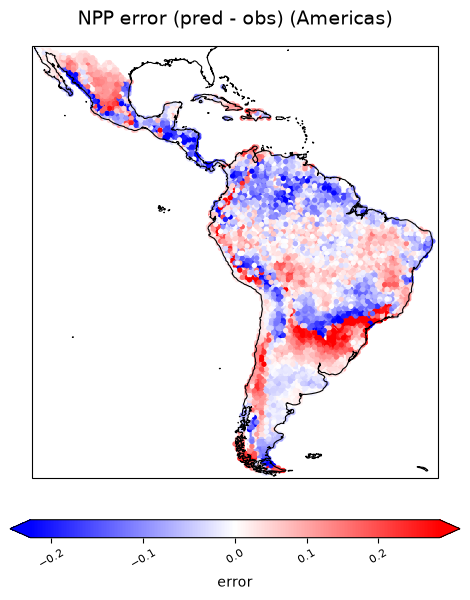

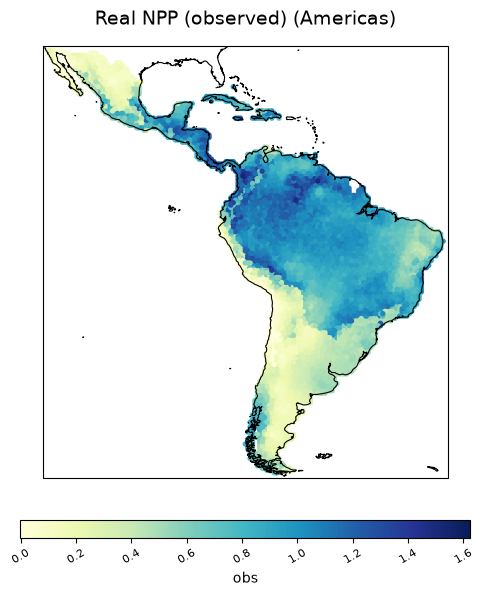

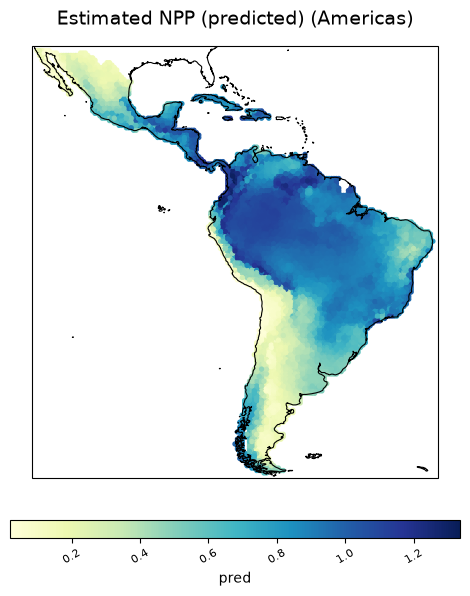

In [11]:
plot_var(preds_npp_am, 'error', title='NPP error (pred - obs)', area='Americas')
plot_var(preds_npp_am, 'obs', title='Real NPP (observed)', area='Americas')
plot_var(preds_npp_am, 'pred', title='Estimated NPP (predicted)', area='Americas')

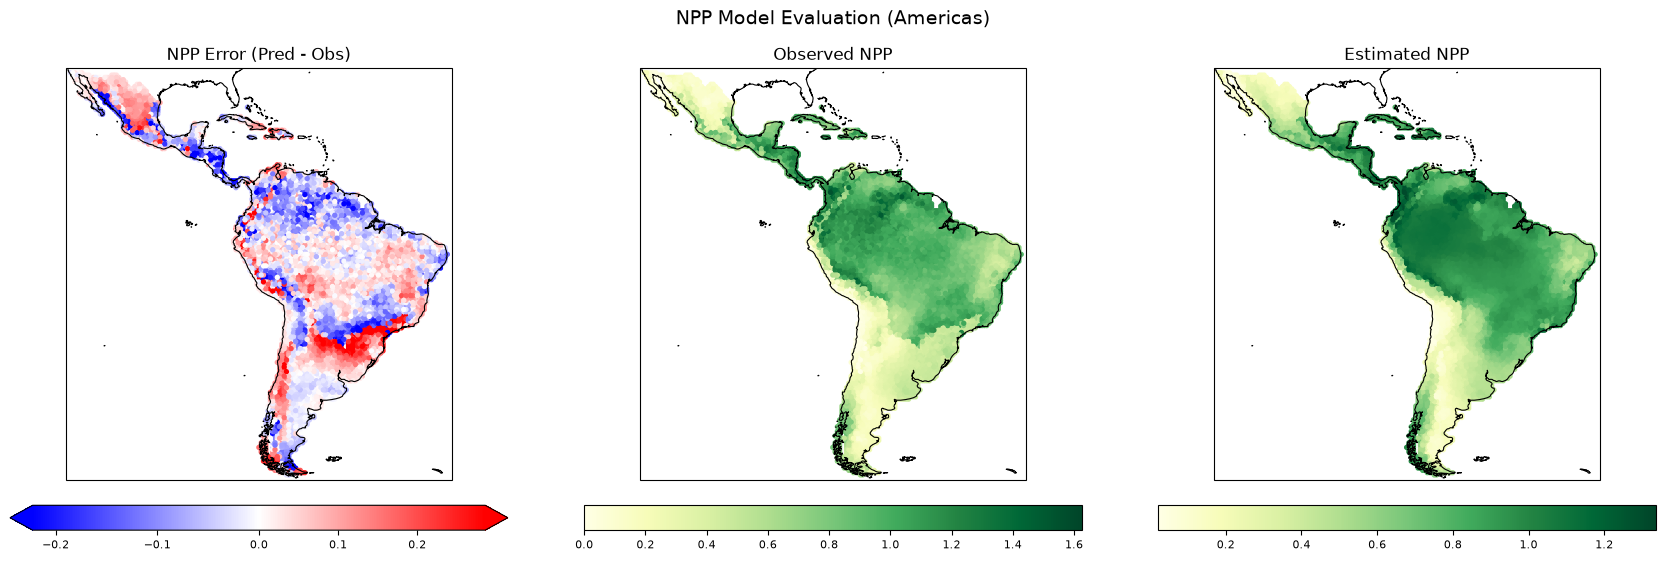

In [21]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import numpy as np

# Setup figure with 3 side-by-side cartopy subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6), subplot_kw=dict(projection=ccrs.PlateCarree()))

variables = ['error', 'obs', 'pred']
titles = ['NPP Error (Pred - Obs)', 'Observed NPP', 'Estimated NPP']

# Calculate spatial extent for the Americas
lon_min, lon_max = preds_npp_am['Lon'].min() - 1, preds_npp_am['Lon'].max() + 1
lat_min, lat_max = preds_npp_am['Lat'].min() - 1, preds_npp_am['Lat'].max() + 1
extent = [lon_min, lon_max, lat_min, lat_max]

for i, (var, title) in enumerate(zip(variables, titles)):
    ax = axes[i]
    ax.coastlines(resolution='50m', linewidth=0.8)
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=12)
    
    # Apply TwoSlopeNorm for error, standard scaling for obs/pred
    is_error = var == 'error'
    if is_error:
        cmap = 'bwr'
        val_min = np.percentile(preds_npp_am[var].dropna(), 2)
        val_max = np.percentile(preds_npp_am[var].dropna(), 98)
        norm = mcolors.TwoSlopeNorm(vmin=min(val_min, -0.001), vcenter=0.0, vmax=max(val_max, 0.001))
        cbar_kwargs = {'extend': 'both'}
    else:
        cmap = 'YlGn'
        norm = None
        cbar_kwargs = {}
        
    # Scatter plot
    sc = ax.scatter(
        preds_npp_am['Lon'], preds_npp_am['Lat'],
        c=preds_npp_am[var],
        cmap=cmap,
        norm=norm,
        s=8,
        transform=ccrs.PlateCarree()
    )
    
    # Add a horizontal colorbar under each subplot
    cbar = fig.colorbar(sc, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8, **cbar_kwargs)
    cbar.ax.tick_params(labelsize=8)

plt.suptitle("NPP Model Evaluation (Americas)", fontsize=14)
plt.tight_layout()
plt.show()

mean error: 0.006778574412613592
0.002603610702431796
0.002603610702431796
95CI: (0.0042, 0.0094)


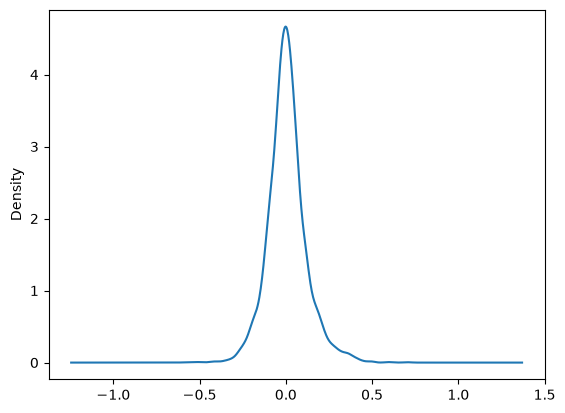

In [32]:
preds_npp_am['error'].plot.kde()

import statsmodels.stats.api as sms

lower, upper = sms.DescrStatsW(preds_npp_am['error']).tconfint_mean()
#print(sms.DescrStatsW(preds_npp_am['error']).)

print("mean error:", preds_npp_am['error'].mean())
print(upper - preds_npp_am['error'].mean())
print(preds_npp_am['error'].mean() - lower)
print(f"95CI: ({lower:.4f}, {upper:.4f})")



##### 4.2 Europe

In [ ]:
test_rmse_npp_eu, cv_scores_npp_eu, preds_npp_eu, model_npp_eu = execute(df_master, area='Europe', target_var='NPP')

BEFORE ENSEMBLE METHOD
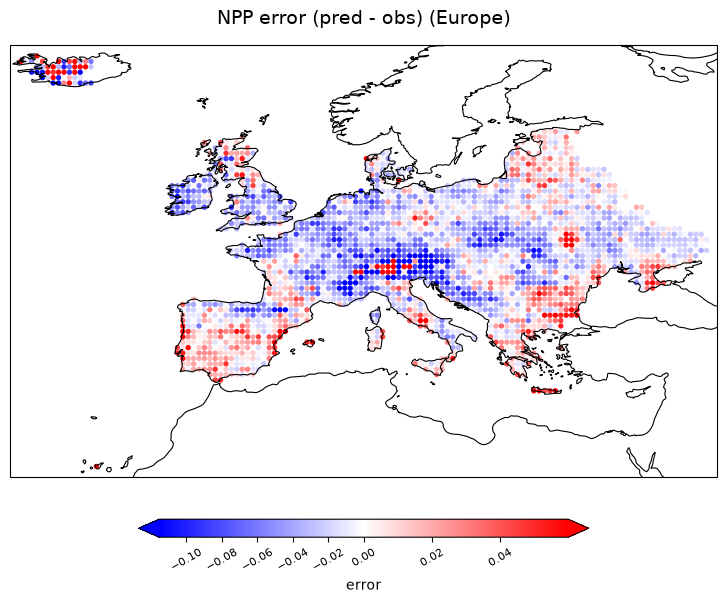

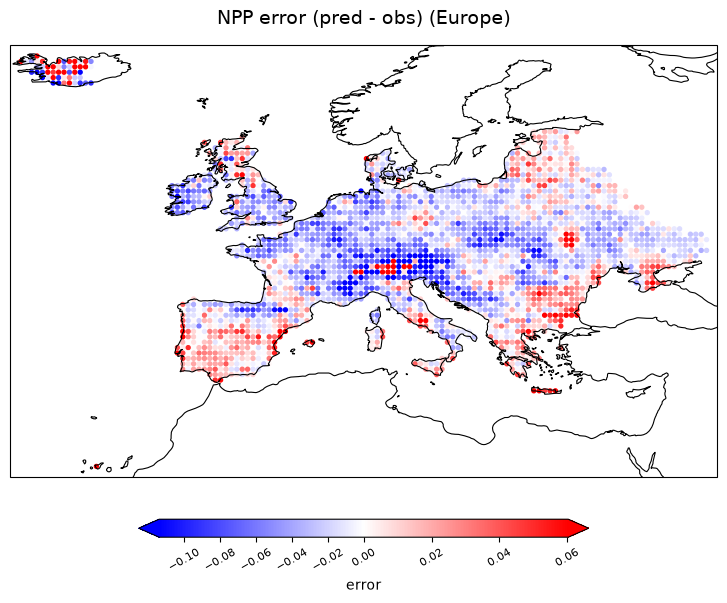

In [13]:
plot_var(preds_npp_eu, 'error', title='NPP error (pred - obs)', area='Europe')

#### 5. VegC regression


##### 5.1 Americas

In [13]:
test_rmse_vegc_am, cv_scores_vegc_am, preds_vegc_am, model_vegc_am = execute(df_master, area='Americas', target_var='VegC')

--- Data Split Summary [VegC | Region: Americas] ---
Train: 43674 entries | Test: 7176 entries
--- Running GroupKFold CV (5 splits) based on spatial groups ---
  Fold 1 Validation RMSE: 1.3995
  Fold 2 Validation RMSE: 1.6182
  Fold 3 Validation RMSE: 1.5728
  Fold 4 Validation RMSE: 1.5377
  Fold 5 Validation RMSE: 1.3252
Mean CV RMSE: 2.2344 +/- 0.3245

Making test predictions using ensemble of spatial fold models...
Finished! Final Held-Out Test RMSE: 3.6456


In [20]:
nrmse_vegc_am = test_rmse_vegc_am / (preds_vegc_am['obs'].max() - preds_vegc_am['obs'].min())
print(nrmse_vegc_am)

0.0792525317816742


mean error: 0.48207201992592247
0.10991629981206846
0.10991629981206846
95CI: (0.3722, 0.5920)


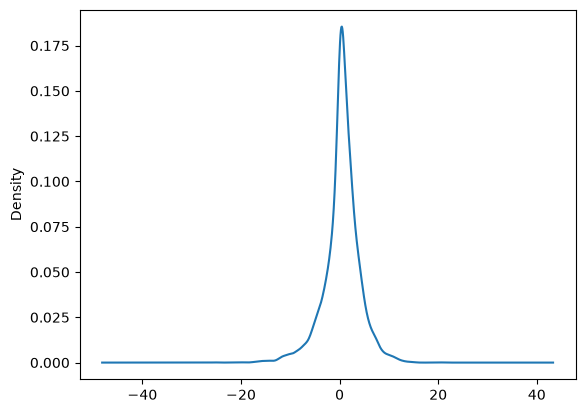

In [35]:
preds_vegc_am['error'].plot.kde()

lower, upper = sms.DescrStatsW(preds_vegc_am['error']).tconfint_mean(alpha=0.01)
#print(sms.DescrStatsW(preds_npp_am['error']).)

print("mean error:", preds_vegc_am['error'].mean())
print(upper - preds_vegc_am['error'].mean())
print(preds_vegc_am['error'].mean() - lower)
print(f"95CI: ({lower:.4f}, {upper:.4f})")

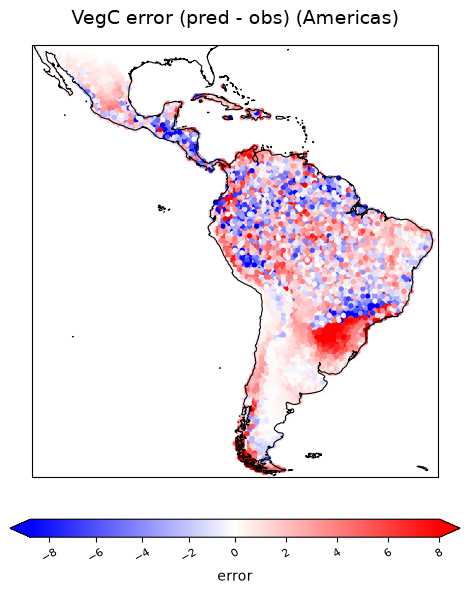

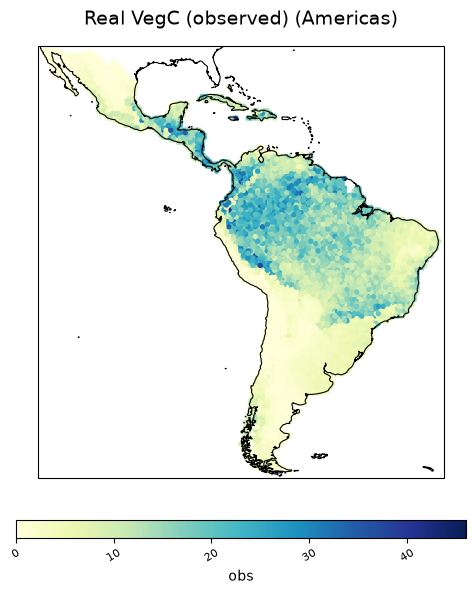

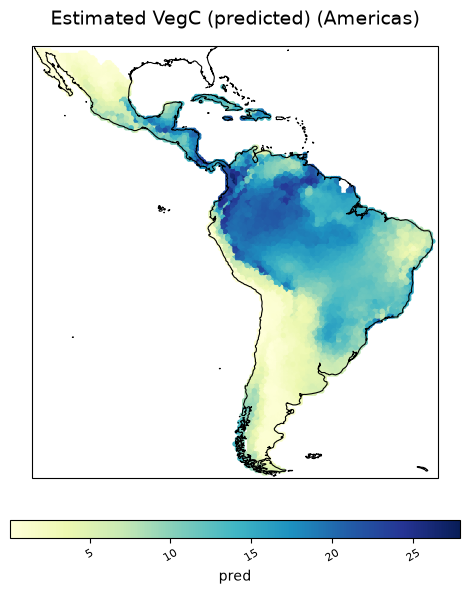

In [14]:
plot_var(preds_vegc_am, 'error',  title='VegC error (pred - obs)', area='Americas')
plot_var(preds_vegc_am, 'obs', title='Real VegC (observed)', area='Americas')
plot_var(preds_vegc_am, 'pred', title='Estimated VegC (predicted)', area='Americas')

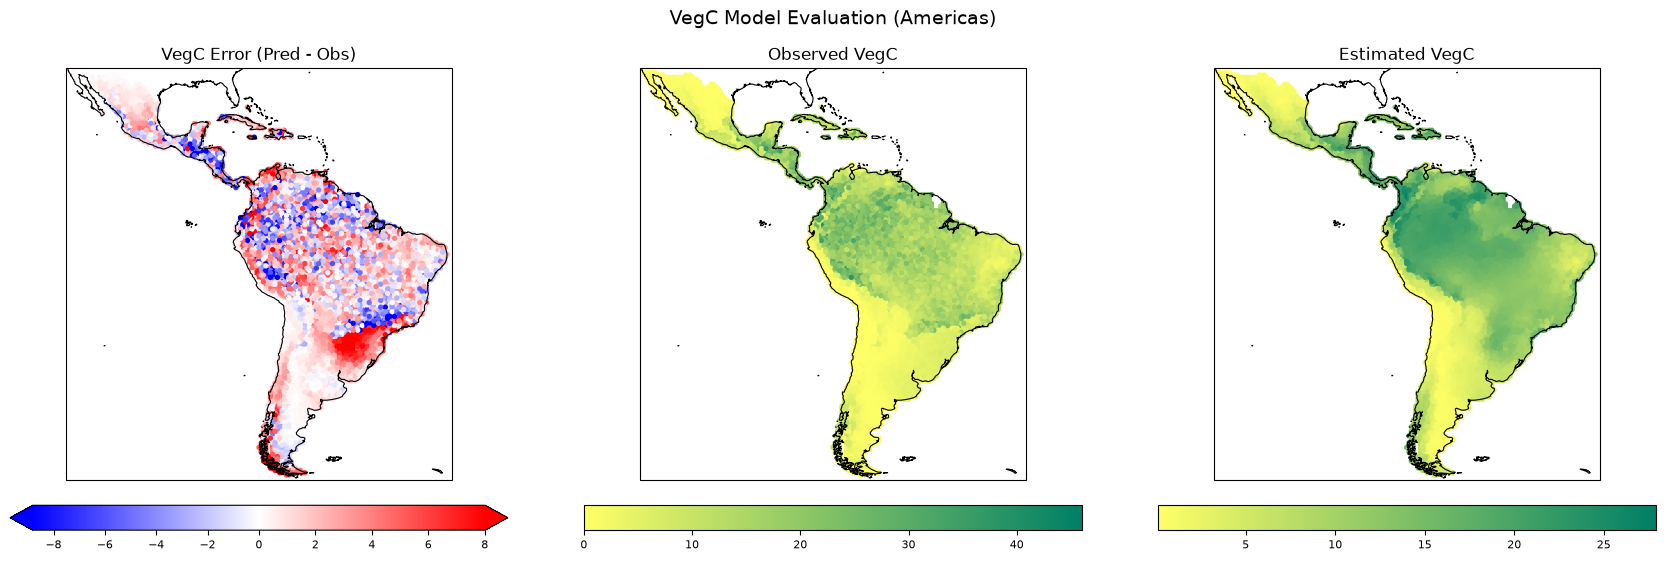

In [23]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import numpy as np

# Setup figure with 3 side-by-side cartopy subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6), subplot_kw=dict(projection=ccrs.PlateCarree()))

variables = ['error', 'obs', 'pred']
titles = ['VegC Error (Pred - Obs)', 'Observed VegC', 'Estimated VegC']

# Calculate spatial extent for the Americas
lon_min, lon_max = preds_vegc_am['Lon'].min() - 1, preds_vegc_am['Lon'].max() + 1
lat_min, lat_max = preds_vegc_am['Lat'].min() - 1, preds_vegc_am['Lat'].max() + 1
extent = [lon_min, lon_max, lat_min, lat_max]

for i, (var, title) in enumerate(zip(variables, titles)):
    ax = axes[i]
    ax.coastlines(resolution='50m', linewidth=0.8)
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=12)
    
    # Apply TwoSlopeNorm for error, standard scaling for obs/pred
    is_error = var == 'error'
    if is_error:
        cmap = 'bwr'
        val_min = np.percentile(preds_vegc_am[var].dropna(), 2)
        val_max = np.percentile(preds_vegc_am[var].dropna(), 98)
        norm = mcolors.TwoSlopeNorm(vmin=min(val_min, -0.001), vcenter=0.0, vmax=max(val_max, 0.001))
        cbar_kwargs = {'extend': 'both'}
    else:
        cmap = 'summer_r'
        norm = None
        cbar_kwargs = {}
        
    # Scatter plot
    sc = ax.scatter(
        preds_vegc_am['Lon'], preds_vegc_am['Lat'],
        c=preds_vegc_am[var],
        cmap=cmap,
        norm=norm,
        s=8,
        transform=ccrs.PlateCarree()
    )
    
    # Add a horizontal colorbar under each subplot
    cbar = fig.colorbar(sc, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8, **cbar_kwargs)
    cbar.ax.tick_params(labelsize=8)

plt.suptitle("VegC Model Evaluation (Americas)", fontsize=14)
plt.tight_layout()
plt.show()

##### 5.2 Europe

In [16]:
test_rmse_vegc_eu, cv_scores_vegc_eu, preds_vegc_eu, model_vegc_eu = execute(df_master, area='Europe', target_var='VegC')

--- Data Split Summary [VegC | Region: Europe] ---
Train: 48465 entries | Test: 2385 entries
--- Running GroupKFold CV (5 splits) based on spatial groups ---
  Fold 1 Validation RMSE: 1.7590
  Fold 2 Validation RMSE: 1.7278
  Fold 3 Validation RMSE: 1.9532
  Fold 4 Validation RMSE: 1.7935
  Fold 5 Validation RMSE: 1.8536
Mean CV RMSE: 3.3094 +/- 0.2937

Making test predictions using ensemble of spatial fold models...
Finished! Final Held-Out Test RMSE: 1.7646


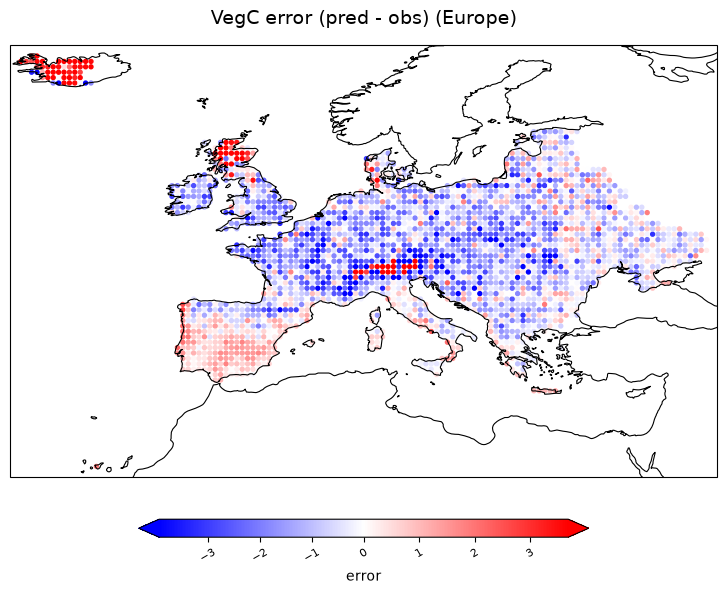

In [17]:
plot_var(preds_vegc_eu, 'error', title='VegC error (pred - obs)', area='Europe')

#### 6. Gridsearch for parameter optimization

In [18]:
# X_train_npp_am, y_train_npp_am, _, _, _ = prepare_spatial_splits(df=df_master, target_var='NPP', test_region='Americas')


# # Define a targeted, lightweight grid
# param_dist = {
#     'n_estimators': [100, 200, 300],
#     'max_depth': [15, 25, None],
#     'max_features': ['sqrt', 0.3, 0.5, 1.0],
#     'min_samples_leaf': [1, 2, 5],
#     'min_samples_split': [2, 5, 10]
# }

# # Fast search using 10 iterations
# rf_search = RandomizedSearchCV(
#     estimator=RandomForestRegressor(random_state=random_seed, n_jobs=-1),
#     param_distributions=param_dist,
#     n_iter=10,
#     scoring='neg_root_mean_squared_error',
#     cv=5,  # Or pass a spatial fold iterator
#     random_state=random_seed,
#     n_jobs=-1,
#     verbose=1
# )

# rf_search.fit(X_train_npp_am, y_train_npp_am)
# print("Best Params:", rf_search.best_params_)
# print("Best CV RMSE:", -rf_search.best_score_)

#### 7. Feature Importance plot

In [43]:
def plot_feature_importance_comparison(models_npp, models_vegc, feature_names, top_n=15):
    # Handle NPP models (list or single)
    if isinstance(models_npp, list):
        imp_npp = pd.Series(np.mean([m.feature_importances_ for m in models_npp], axis=0), index=feature_names)
    else:
        imp_npp = pd.Series(models_npp.feature_importances_, index=feature_names)
        
    # Handle VegC models (list or single)
    if isinstance(models_vegc, list):
        imp_vegc = pd.Series(np.mean([m.feature_importances_ for m in models_vegc], axis=0), index=feature_names)
    else:
        imp_vegc = pd.Series(models_vegc.feature_importances_, index=feature_names)
    
    # Combine into a DataFrame and sort by maximum importance
    df_imp = pd.DataFrame({'NPP': imp_npp, 'VegC': imp_vegc})
    df_imp['Max_Imp'] = df_imp.max(axis=1)
    df_top = df_imp.sort_values(by='Max_Imp', ascending=True).tail(top_n)
    
    # Plot side-by-side
    fig, ax = plt.subplots(figsize=(10, 8))
    y = np.arange(len(df_top))
    height = 0.35
    
    ax.barh(y + height/2, df_top['NPP'], height, label='NPP Model', color='#0F4761')
    ax.barh(y - height/2, df_top['VegC'], height, label='VegC Model', color='#d95f02')
    
    ax.set_yticks(y)
    ax.set_yticklabels(df_top.index)
    ax.set_xlabel('Gini Feature Importance')
    ax.set_title(f'Top {top_n} Feature Importances: NPP vs VegC Random Forest Models')
    ax.legend()
    ax.grid(axis='x', linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

In [41]:
def feature_importance_for1(models, feature_names, top_n=15, title=''):
    # If a list of fold models is passed, average their feature importances
    if isinstance(models, list):
        importances = np.mean([m.feature_importances_ for m in models], axis=0)
    else:
        importances = models.feature_importances_

    imp = pd.Series(importances, index=feature_names)
    imp = imp.sort_values(ascending=True).tail(top_n)
    y = np.arange(len(imp))
    height = 0.35

    plt.figure(figsize=(10, 8))
    plt.barh(y + height/2, imp, color="#0F4761")
    plt.xlabel('Gini Feature Importance')
    plt.yticks(y, labels=imp.index)
    plt.grid(axis='x', alpha=0.6, linestyle=':')
    plt.title(title)
    plt.tight_layout()
    plt.show()

--- Data Split Summary [NPP | Region: Americas] ---
Train: 43674 entries | Test: 7176 entries


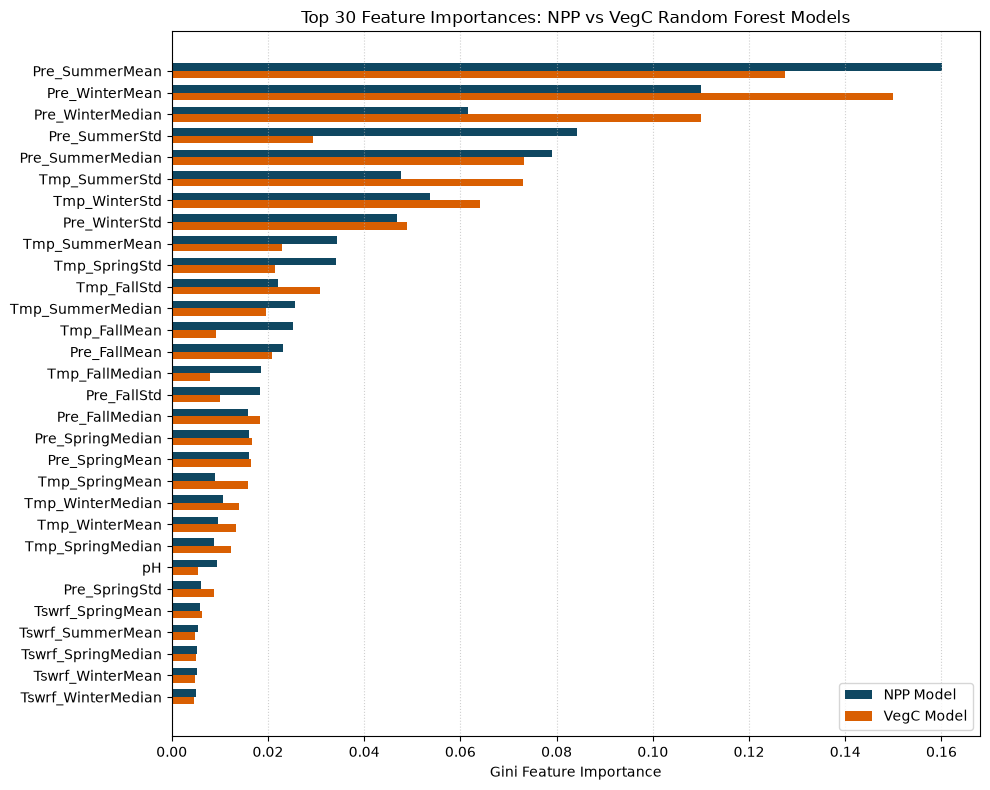

In [44]:
# Get X_train data, just for column names
X_train_npp_am, _, _, _, _ = prepare_spatial_splits(df=df_master, target_var='NPP', test_region='Americas')

# Plot feature importance for both models
plot_feature_importance_comparison(model_npp_am, model_vegc_am, X_train_npp_am.columns, top_n=30)

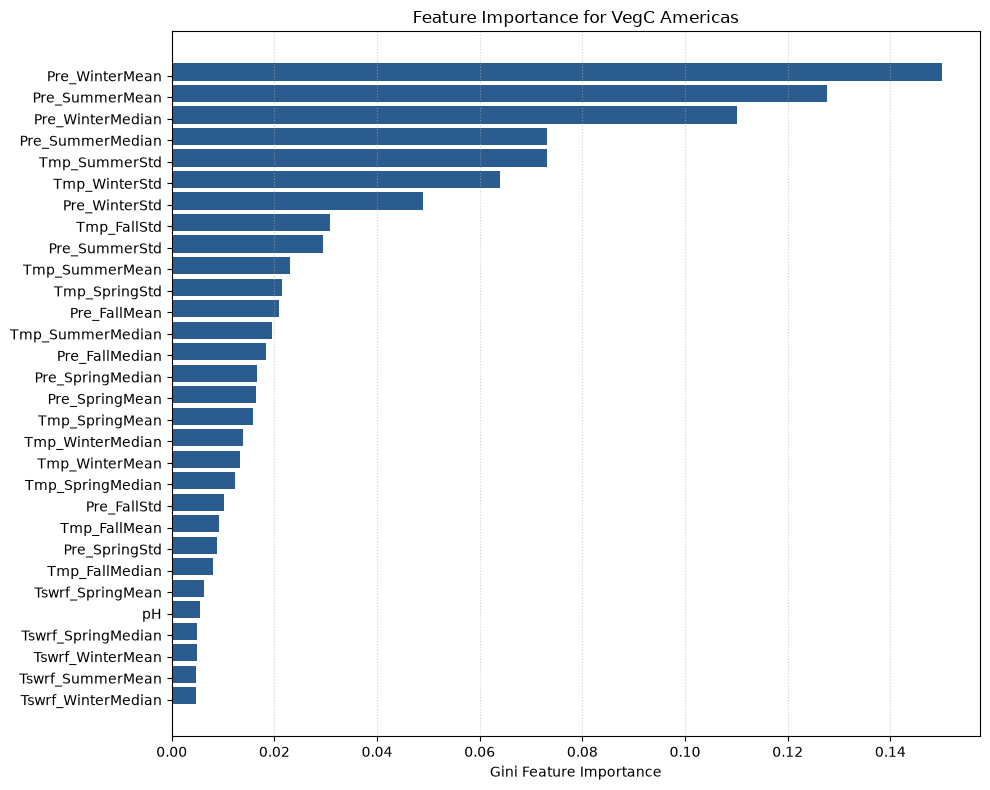

In [22]:
feature_importance_for1(model_vegc_am, X_train_npp_am.columns, 30, title='Feature Importance for VegC Americas')


#### 8. Scatterplots

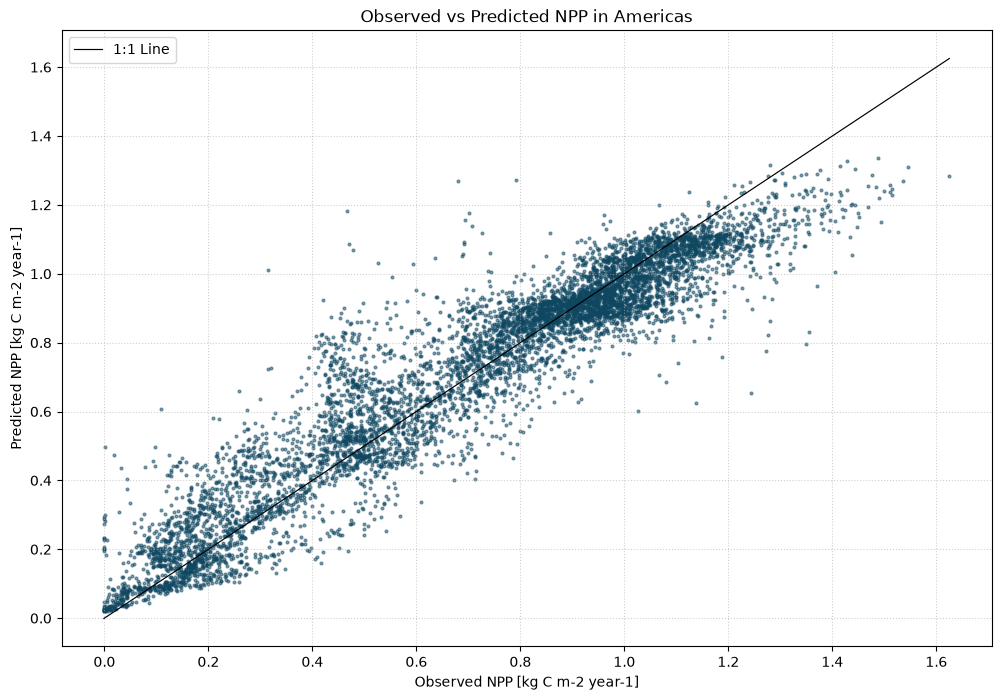

In [36]:
area = 'Americas'
plt.figure(figsize=(12, 8))
plt.scatter(preds_npp_am['obs'], preds_npp_am['pred'], s=4, alpha=0.5, c='#0F4761')

# Determine global min and max to span the full plot range
min_val = min(preds_npp_am['obs'].min(), preds_npp_am['pred'].min())
max_val = max(preds_npp_am['obs'].max(), preds_npp_am['pred'].max())

# Add 1:1 reference line
plt.plot([min_val, max_val], [min_val, max_val], color='black', linewidth=0.85, label='1:1 Line')

plt.xlabel('Observed NPP [kg C m-2 year-1]')
plt.ylabel('Predicted NPP [kg C m-2 year-1]')
plt.title(f'Observed vs Predicted NPP in {area}')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

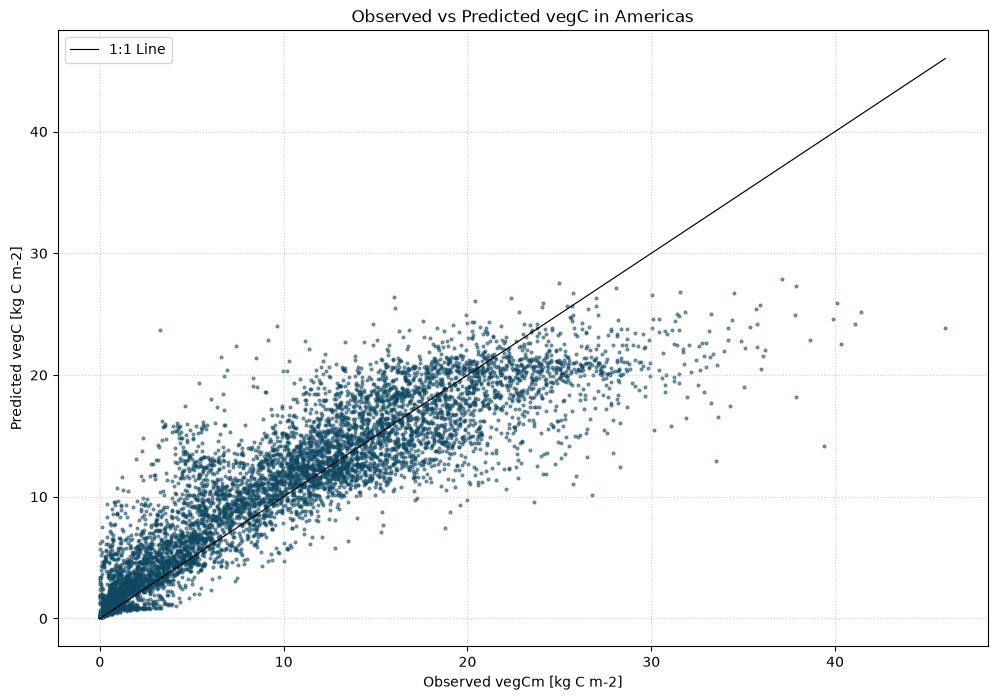

In [37]:
plt.figure(figsize=(12, 8))
plt.scatter(preds_vegc_am['obs'], preds_vegc_am['pred'], s=4, alpha=0.5, color='#0F4761')

# Determine global min and max to span the full plot range
min_val = min(preds_vegc_am['obs'].min(), preds_vegc_am['pred'].min())
max_val = max(preds_vegc_am['obs'].max(), preds_vegc_am['pred'].max())

# Add 1:1 reference line
plt.plot([min_val, max_val], [min_val, max_val], color='black', linewidth=0.85, label='1:1 Line')

plt.xlabel('Observed vegCm [kg C m-2]')
plt.ylabel('Predicted vegC [kg C m-2]')
plt.title(f'Observed vs Predicted vegC in {area}')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


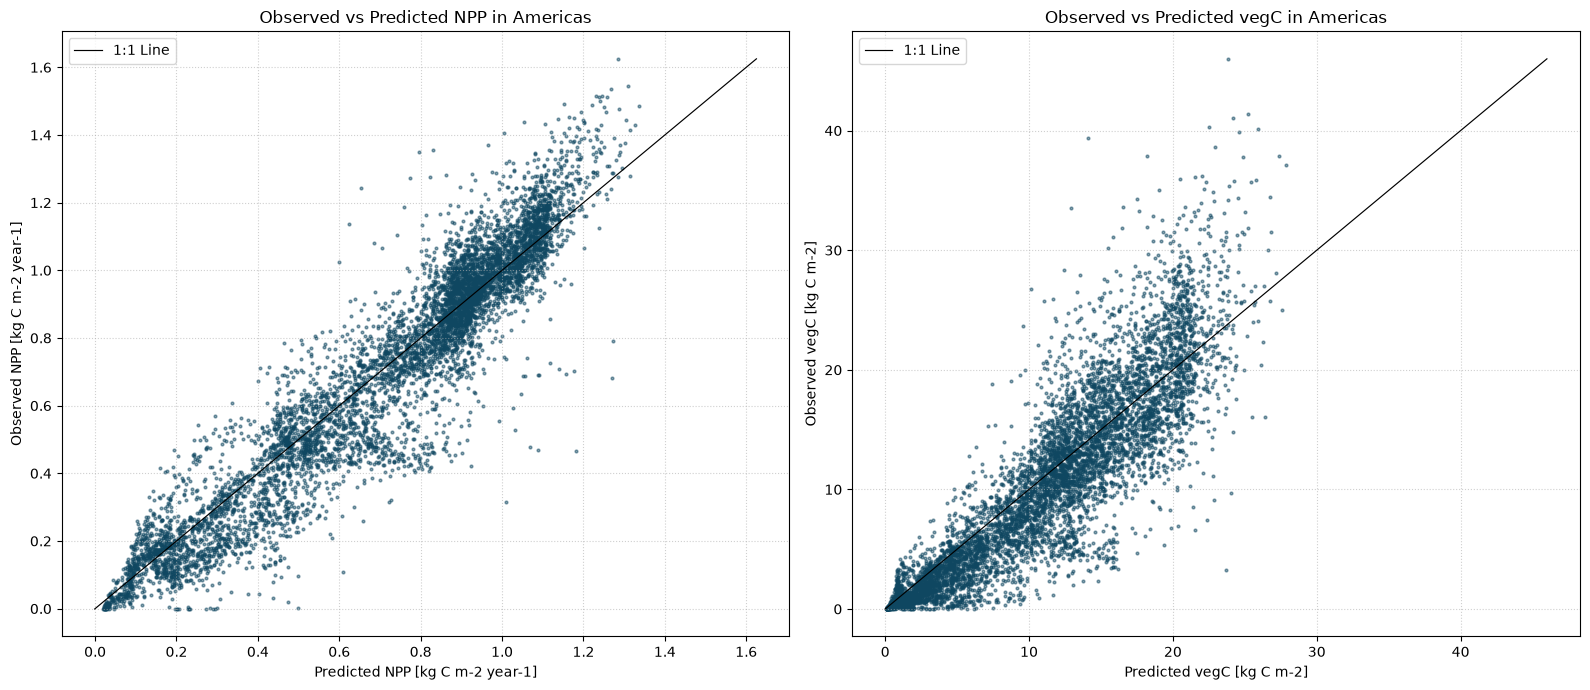

In [40]:
area = 'Americas'
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# --- Panel 1: NPP (Swapped axes) ---
ax1.scatter(preds_npp_am['pred'], preds_npp_am['obs'], s=4, alpha=0.5, c='#0F4761')

min_val_npp = min(preds_npp_am['obs'].min(), preds_npp_am['pred'].min())
max_val_npp = max(preds_npp_am['obs'].max(), preds_npp_am['pred'].max())
ax1.plot([min_val_npp, max_val_npp], [min_val_npp, max_val_npp], color='black', linewidth=0.85, label='1:1 Line')

ax1.set_xlabel('Predicted NPP [kg C m-2 year-1]')
ax1.set_ylabel('Observed NPP [kg C m-2 year-1]')
ax1.set_title(f'Observed vs Predicted NPP in {area}')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# --- Panel 2: vegC (Swapped axes) ---
ax2.scatter(preds_vegc_am['pred'], preds_vegc_am['obs'], s=4, alpha=0.5, color='#0F4761')

min_val_vegc = min(preds_vegc_am['obs'].min(), preds_vegc_am['pred'].min())
max_val_vegc = max(preds_vegc_am['obs'].max(), preds_vegc_am['pred'].max())
ax2.plot([min_val_vegc, max_val_vegc], [min_val_vegc, max_val_vegc], color='black', linewidth=0.85, label='1:1 Line')

ax2.set_xlabel('Predicted vegC [kg C m-2]')
ax2.set_ylabel('Observed vegC [kg C m-2]')
ax2.set_title(f'Observed vs Predicted vegC in {area}')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

#### 9. Exploration: why is the RFR hitting a ceiling?

In [3]:
spatial_folds = pd.read_csv('Spatial_folds.csv')

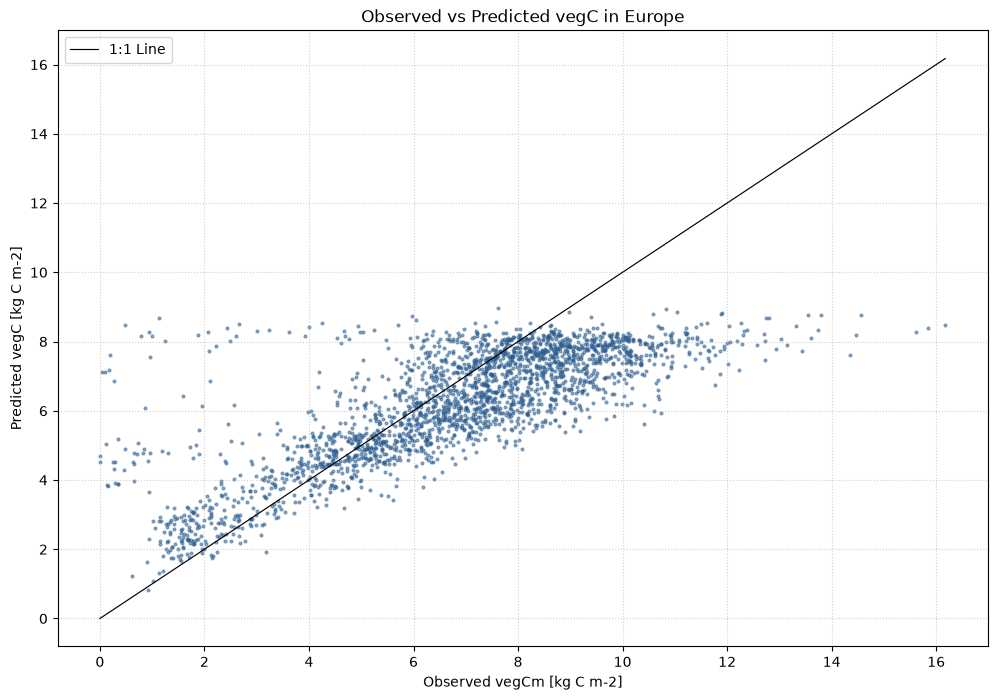

In [25]:
area='Europe'
plt.figure(figsize=(12, 8))
plt.scatter(preds_vegc_eu['obs'], preds_vegc_eu['pred'], s=4, alpha=0.5, color='#2b5c8f')

# Determine global min and max to span the full plot range
min_val = min(preds_vegc_eu['obs'].min(), preds_vegc_eu['pred'].min())
max_val = max(preds_vegc_eu['obs'].max(), preds_vegc_eu['pred'].max())

# Add 1:1 reference line
plt.plot([min_val, max_val], [min_val, max_val], color='black', linewidth=0.85, label='1:1 Line')

plt.xlabel('Observed vegCm [kg C m-2]')
plt.ylabel('Predicted vegC [kg C m-2]')
plt.title(f'Observed vs Predicted vegC in {area}')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

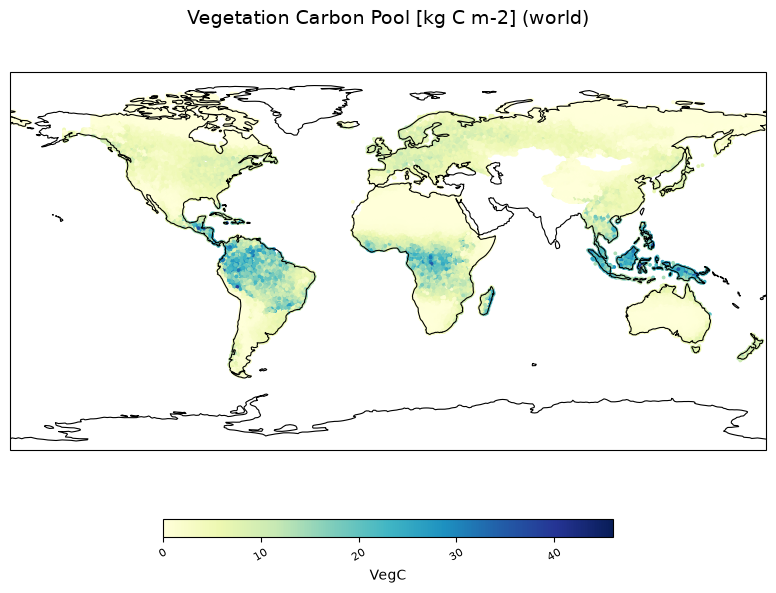

In [26]:
plot_var(df_master, 'VegC', title='Vegetation Carbon Pool [kg C m-2]')

In [27]:
print('Max predicted value in Europe:', preds_vegc_eu['pred'].max())
print('Max observed value in Europe:', preds_vegc_eu['obs'].max())

Max predicted value in Europe: 8.967193177682336
Max observed value in Europe: 16.175


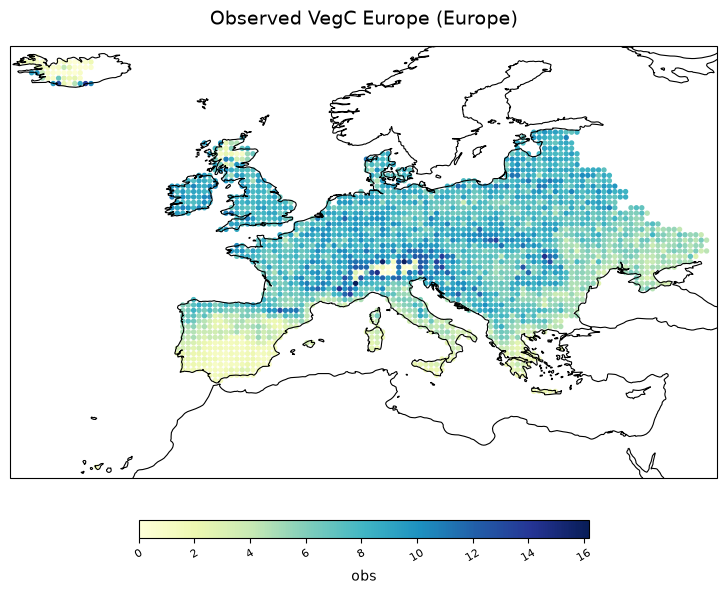

In [28]:
plot_var(preds_vegc_eu, 'obs', title='Observed VegC Europe', area='Europe')

In [29]:
#test_rmse_vegc_rus, cv_scores_vegc_rus, preds_vegc_rus, model_vegc_rus = execute(df_master, area='Russia', target_var='VegC')

In [30]:
# plot_var(preds_vegc_rus, 'error', title='VegC error')

In [31]:
test_rmse_vegc_eu0, cv_scores_vegc_eu0, preds_vegc_eu0, model_vegc_eu0 = execute(df_master, area='Europe', target_var='VegC', spatialCV=False)

--- Data Split Summary [VegC | Region: Europe] ---
Train: 48465 entries | Test: 2385 entries
--- Running standard KFold CV (5 splits) ---
  Fold 1 Validation RMSE: 1.6813
  Fold 2 Validation RMSE: 1.6358
  Fold 3 Validation RMSE: 1.6500
  Fold 4 Validation RMSE: 1.6964
  Fold 5 Validation RMSE: 1.7455
Mean CV RMSE: 2.8300 +/- 0.1302

Making test predictions using ensemble of spatial fold models...
Finished! Final Held-Out Test RMSE: 1.7587


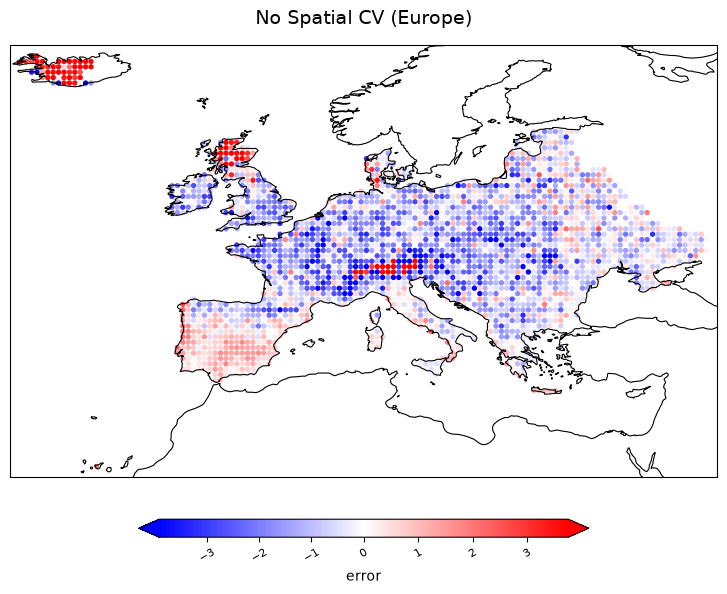

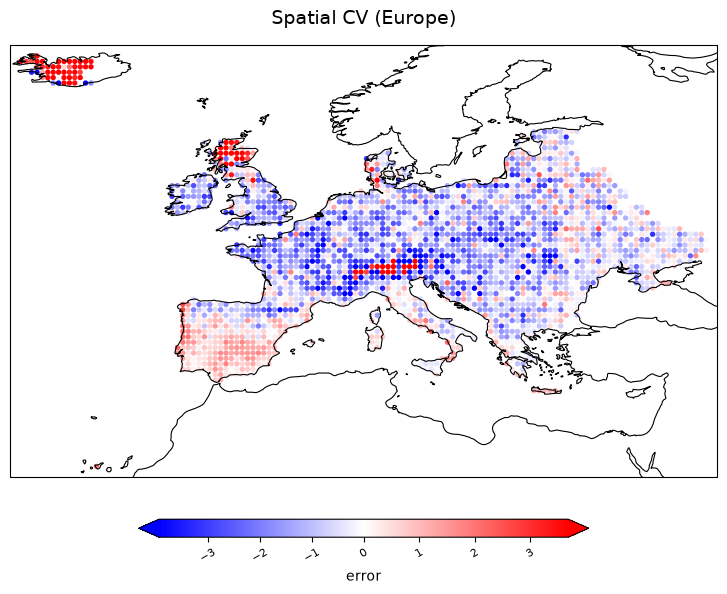

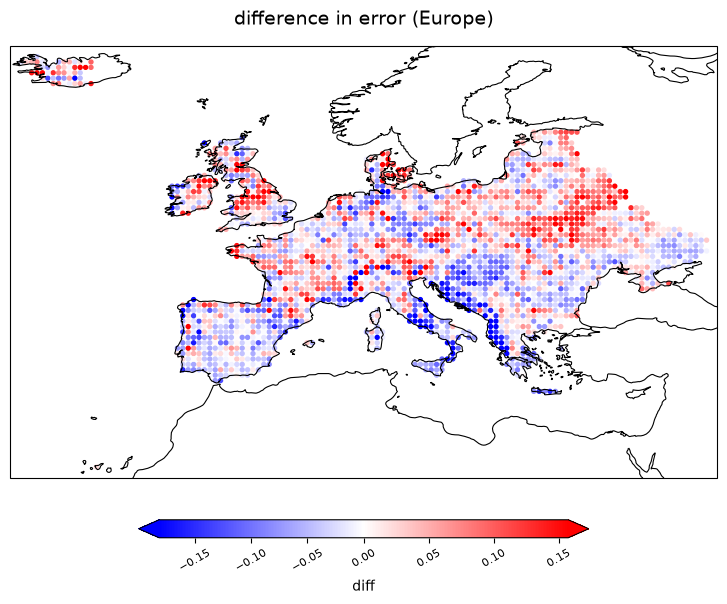

In [32]:
plot_var(preds_vegc_eu0, 'error', title='No Spatial CV', area='Europe')
plot_var(preds_vegc_eu, 'error', title='Spatial CV', area='Europe')

difference = preds_vegc_eu0.copy()
difference['diff'] = preds_vegc_eu0['error'] - preds_vegc_eu['error']



plot_var(difference, 'diff', title='difference in error', area='Europe')

In [33]:
print('Spatial CV rmse:', test_rmse_vegc_eu)
print('Non Spatial CV rmse:', test_rmse_vegc_eu0)

Spatial CV rmse: 1.7646070748276521
Non Spatial CV rmse: 1.7587344814651176
